In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import  train_model, plot_loss, plot_mae, evaluate_model #build_nn_model

from sklearn.model_selection import train_test_split
from numpy.lib.stride_tricks import sliding_window_view

import tensorflow as tf
from sklearn.preprocessing import StandardScaler

from pandas import DataFrame
from pandas import concat

<h3>Importing The Data

,Unnamed: 0,point,time,x,y,x_rb,y_rb,s0,s1,s2,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
0,0,0.0,1.2720,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
1,1,1.0,2.6999,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,...,260.0,6.0,154.0,120.0,434.0,400.0,0.0,0.0,0.000000,0.000000
2,2,0.0,23.0354,1.2,1.2,1.200031,1.2,6144.0,-8393.0,2249.0,...,72.0,6.0,-60.0,-68.0,220.0,212.0,-214.0,-188.0,1.945455,1.709091
3,3,1.0,25.1267,1.1,1.2,1.099897,1.2,6144.0,-7949.0,1805.0,...,76.0,6.0,-46.0,-64.0,234.0,216.0,-200.0,-184.0,1.818182,1.672727
4,4,2.0,27.2019,1.0,1.2,0.999989,1.2,6144.0,-7506.0,1362.0,...,76.0,6.0,-32.0,-64.0,248.0,216.0,-186.0,-184.0,1.690909,1.672727


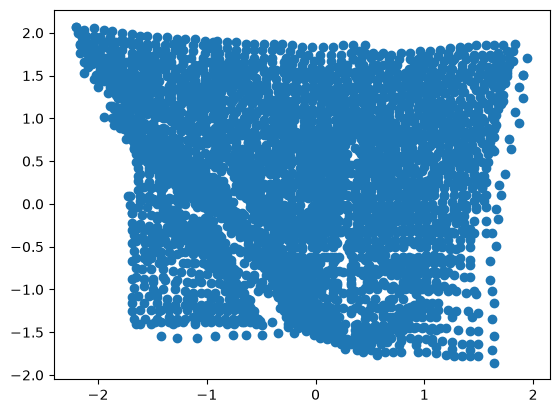

In [33]:
data_concat = pd.read_csv("processed_data/16Oct_data_corrected.csv")
display(data_concat.head())
data_concat.dtypes
plt.scatter(data_concat["cx_mm"], data_concat["cy_mm"])

<h3>Correcting The Data - Remove NaNs and convert to float32

In [34]:
data_concat = data_concat.astype("float32")
data_concat = data_concat.dropna()

<h3>Windowed MLP - Inverse 

In [35]:
dataset = data_concat[["cx_mm", "cy_mm", "s0", "s1", "s2"]].reset_index(drop=True) #reset indexes as multiple datapoints combined
inputs = data_concat[["cx_mm", "cy_mm"]]
outputs = data_concat[["s0", "s1", "s2"]]

In [36]:
# WINDOW_LEN = 3

# cx_mm = inputs["cx_mm"].values.reshape(-1, 1)
# cy_mm = inputs["cy_mm"].values.reshape(-1, 1)

# # create position windows...
# cx_mm_window = sliding_window_view(cx_mm, WINDOW_LEN, 0).squeeze()
# cy_mm_window = sliding_window_view(cy_mm, WINDOW_LEN, 0).squeeze()

# # cxcy_window = np.concatenate([cx_mm_window, cy_mm_window], axis=1)

# print(f"Original input (position only): {inputs.shape}")
# print(f"New input (position history): {cxcy_window.shape}")

In [37]:
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
	"""
	Frame a time series as a supervised learning dataset.
	Arguments:
		data: Sequence of observations as a list or NumPy array.
		n_in: Number of lag observations as input (X).
		n_out: Number of observations as output (y).
		dropnan: Boolean whether or not to drop rows with NaN values.
	Returns:
		Pandas DataFrame of series framed for supervised learning.
	"""
	n_vars = 1 if type(data) is list else data.shape[1]
	df = DataFrame(data)
	cols, names = list(), list()
	# input sequence (t-n, ... t-1)
	for i in range(n_in, 0, -1):
		cols.append(df.shift(i))
		names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
	# forecast sequence (t, t+1, ... t+n)
	for i in range(0, n_out):
		cols.append(df.shift(-i))
		if i == 0:
			names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
		else:
			names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
	# put it all together
	agg = concat(cols, axis=1)
	agg.columns = names
	# drop rows with NaN values
	if dropnan:
		agg.dropna(inplace=True)
	return agg

In [38]:
values = dataset.values

cxcy_window = series_to_supervised(dataset,10,1)

cols_to_drop = cxcy_window.filter(regex="var3|4|5.*")
inputs = cxcy_window.drop(list(cols_to_drop), axis=1)

cxcy_window = cxcy_window.rename(columns={"var3(t)": "s0(t)", "var4(t)": "s1(t)", "var5(t)": "s2(t)"})
outputs = cxcy_window[["s0(t)","s1(t)","s2(t)"]] #calculate s2(t) from s2 = -(s0 + s1)

display(outputs.head(1))
display(inputs.head(1))

,s0(t),s1(t),s2(t)
10,6144.0,-4846.0,-1298.0


,var1(t-10),var2(t-10),var1(t-9),var2(t-9),var1(t-8),var2(t-8),var1(t-7),var2(t-7),var1(t-6),var2(t-6),var1(t-3),var2(t-3),var1(t-2),var2(t-2),var1(t-1),var2(t-1),var1(t),var2(t)
10,0.0,0.0,0.0,0.0,1.945455,1.709091,1.818182,1.672727,1.690909,1.672727,1.163636,1.6,1.0,1.581818,0.854545,1.581818,0.690909,1.563636


don't window output motor values

In [39]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(128, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

In [40]:
X_train, X_test, y_train_all, y_test_all = train_test_split(
    inputs, outputs, test_size=0.2, random_state=42, shuffle=False
)
# print(y_train_all)
y_train = y_train_all[["s0(t)", "s1(t)"]] #calculate s2 from s2 = -(s0 + s1) to ensure they all sum to 0
y_test = y_test_all[["s0(t)", "s1(t)"]]

scalerX = StandardScaler().fit(X_train)
scalerY = StandardScaler().fit(y_train)

X_train_scaled = scalerX.transform(X_train)
y_train_scaled = scalerY.transform(y_train)

X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)


model = build_nn_model(X_train_scaled.shape[1], y_train_scaled.shape[1])
model.summary() #investigate

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,330 (106.76 KB)

 Trainable params: 27,330 (106.76 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
history = train_model(model, X_train_scaled, y_train_scaled, verbose=1, epochs=50)

Epoch 1/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1348 - mae: 0.2144 - val_loss: 0.0324 - val_mae: 0.1158
Epoch 2/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0158 - mae: 0.0791 - val_loss: 0.0283 - val_mae: 0.1285
Epoch 3/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0111 - mae: 0.0707 - val_loss: 0.0235 - val_mae: 0.1059
Epoch 4/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0081 - mae: 0.0603 - val_loss: 0.0194 - val_mae: 0.1034
Epoch 5/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0069 - mae: 0.0574 - val_loss: 0.0193 - val_mae: 0.1040
Epoch 6/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0057 - mae: 0.0531 - val_loss: 0.0164 - val_mae: 0.0960
Epoch 7/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0051 - mae: 0.0512 - val_loss: 0.0132 - val_mae: 0.0733
Epoch 8/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0044 - mae: 0.0473 - val_loss: 0.0145 - val_mae: 0.0843
Epoch 9/50
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0040 - mae: 

In [42]:
y_pred = model.predict(X_test_scaled, verbose=0)
evaluate_model("Windowed MLP", y_test_scaled, y_pred, is_scaled=True)


Windowed MLP Results (scaled):
  Overall R2:  0.9156
  Weighted R2: 0.9153


(0.9155800342559814, 0.9152671694755554)

0.0016387855866923928


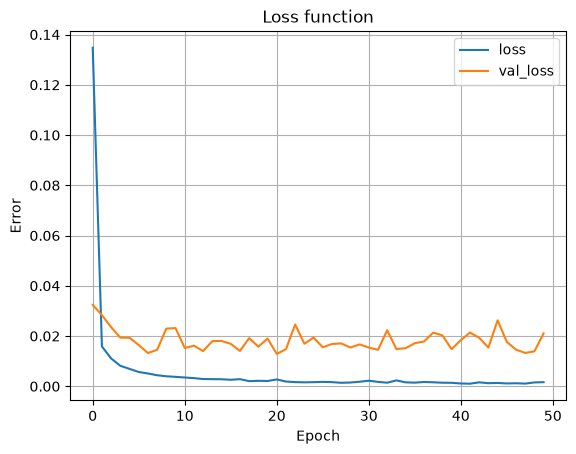

In [43]:
plot_loss(history)
print(history.history['loss'][-1])

0.029525116086006165


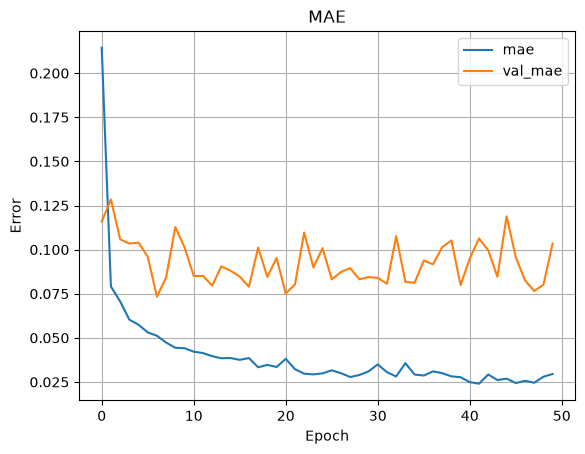

In [44]:
plot_mae(history)
print(history.history['mae'][-1])

In [45]:
test_results_dnn_standard = model.evaluate(X_test_scaled, y_test_scaled, verbose=0)
test_results_dnn_standard

[0.0880860835313797, 0.2280709594488144]

711 711


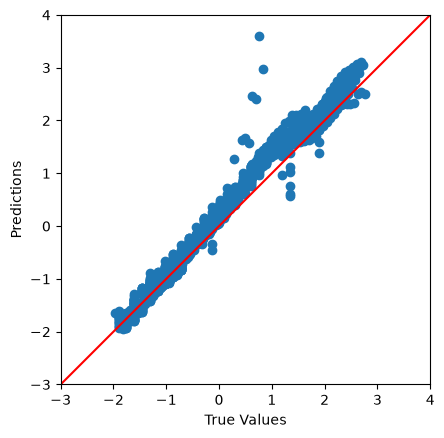

In [46]:
#make predictions with dnn model
#y_pred = model.predict(X_test_scaled, verbose=0)

a = plt.axes(aspect='equal')
plt.scatter(y_test_scaled, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-3, 4]
plt.xlim(lims)
plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

high r2 score.

Predictions are also pretty good, with only a couple that are slightly off.
Possibly overfitting to this data. 

In [47]:
y_pred_inverse = scalerY.inverse_transform(y_pred)
y_test_inverse = scalerY.inverse_transform(y_test_scaled)

711 711


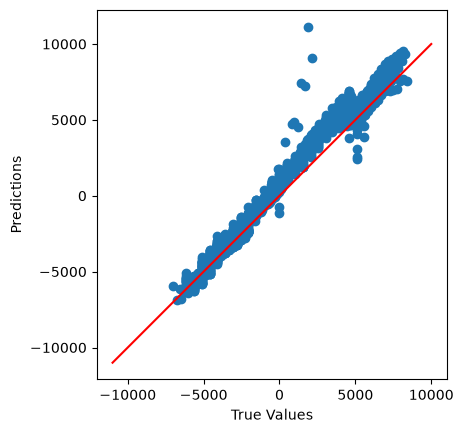

In [48]:
a = plt.axes(aspect='equal')
plt.scatter(y_test_inverse, y_pred_inverse)
plt.xlabel('True Values')
plt.ylabel('Predictions')
lims = [-11000, 10000]
# plt.xlim(lims)
# plt.ylim(lims)
_ = plt.plot(lims, lims, color="red")
plt.title("")
print(len(y_test_scaled), len(y_pred))

In [49]:
y_pred_inverse = DataFrame(y_pred_inverse)

y_pred_inverse[2]= -(y_pred_inverse[0] + y_pred_inverse[1])
y_pred_inverse[0]
y_test


,s0(t),s1(t)
2851,-2048.0,581.0
2852,-2048.0,359.0
2853,-2048.0,137.0
2854,-2048.0,-85.0
2855,-2048.0,-306.0
...,...,...
3557,-5120.0,5664.0
3558,-5120.0,6551.0
3559,-5120.0,6994.0
3560,0.0,0.0


Text(0.5, 0.98, '16th Oct Windowed Test Predictions not flattened')

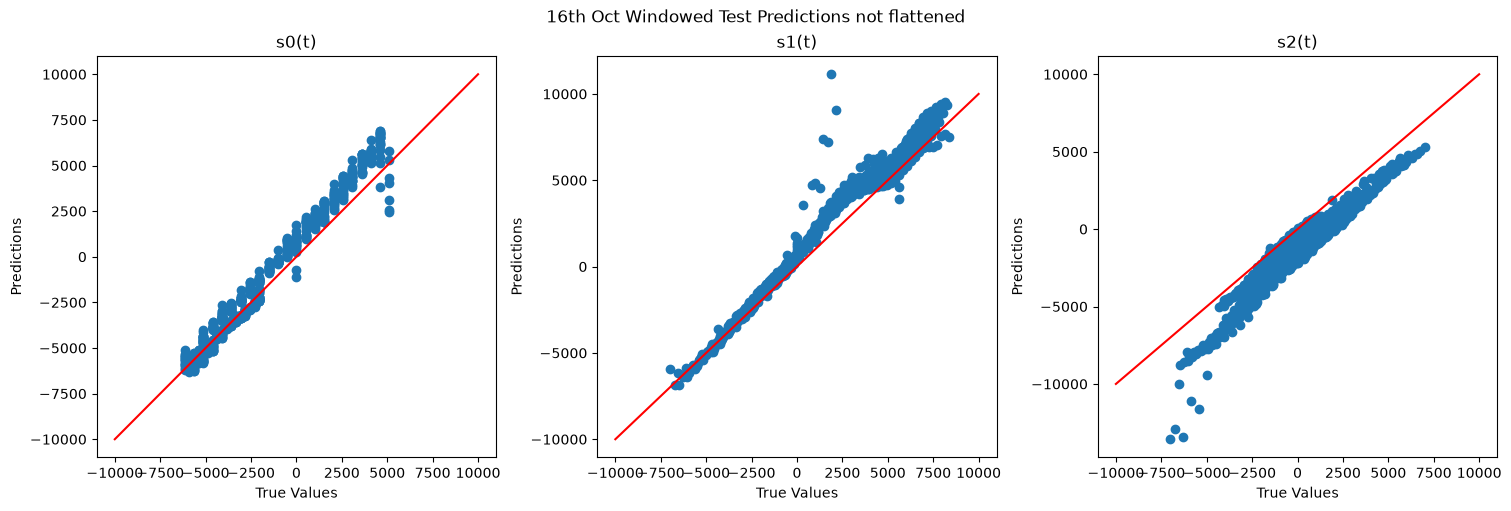

In [50]:
fig, axs = plt.subplots(1,3, figsize=(15,5), constrained_layout=True)


for i, label in enumerate(['s0(t)', 's1(t)', 's2(t)']):
    subplot = axs[i]
    subplot.scatter(y_test_all[label], y_pred_inverse[i])
    lims = [-10000, 10000]
    subplot.set_xlabel('True Values')
    subplot.set_ylabel('Predictions')
    # subplot.set_xlim(lims)
    # subplot.set_ylim(lims)
    _ =subplot.plot(lims, lims, color="red")
    subplot.set_title(label)
fig.suptitle("16th Oct Windowed Test Predictions not flattened")

<h1> Testing with data from 27Oct - Dataset 2

CREATE WINDOW DATA

In [51]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
mesh0045_27Oct_nonans = mesh0045_27Oct.dropna()


NameError: name 'j' is not defined

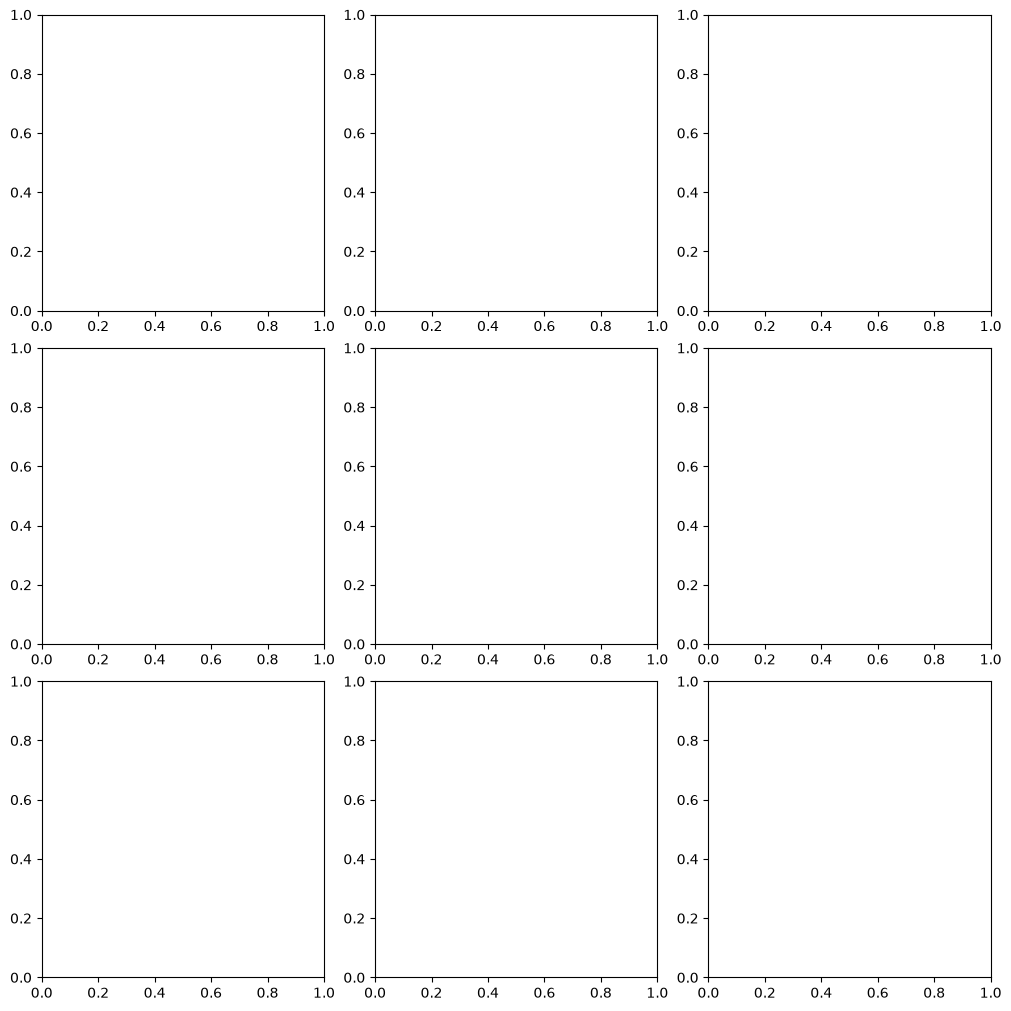

In [52]:
fig, axs = plt.subplots(3, 3, figsize=(10,10), constrained_layout=True)
k = 1
for label in enumerate(['s0', 's1', 's2']):

        subplot = axs[i,j]
        subplot.scatter(y_test_scaled[:, k], y_pred[:, k])
        lims = [-2.8, 2.8]
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        subplot.set_xlim(lims)
        subplot.set_ylim(lims)
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(label)
        k = k+1
fig.suptitle("16th Oct Test Predictions not flattened")


fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45_scaled[:, i],pred_27Oct_45[:, i])
    lims = [-3, 3]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
    k = k+3
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset. Using NN trained on 16thOct Dataset Windowed -1,0,+1")

In [ ]:
#evaluate with first scan of 27th Oct

evaluate_model("Standard NN Inverse on 27Oct Dataset 45 Windowed", true_values_27Oct_45_scaled, pred_27Oct_45_scaled, is_scaled=True)


In [ ]:
true_values_27Oct_45_dropped = true_values_27Oct_45.drop([0,624])

In [ ]:
pred_27Oct_45 = scalerY.inverse_transform(pred_27Oct_45_scaled)

k = 1
pred_27Oct_45[:, k].shape
fig, axs = plt.subplots(1, 3, figsize=(10,5), constrained_layout=True)
for i, label in enumerate(['s0', 's1', 's2']):
    axs[i].scatter(true_values_27Oct_45_dropped[label], pred_27Oct_45[:, k])
    lims = [-10000, 10000]
    axs[i].set_xlabel('True Values')
    axs[i].set_ylabel('Predictions')
    axs[i].set_xlim(lims)
    axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")
    axs[i].set_title(label)
    k = k + 3 #want predictions at index 1, 4 and 7
fig.suptitle("Predictions on scan 0045_dmesh from 27Oct Dataset Windowed. Using NN trained on 16thOct Dataset")

In [ ]:
# np.savetxt("16Oct_MLP_Window_Pred_27Oct_Scan0045_Scaled.csv", pred_27Oct_45, delimiter=',')

<h2> Predicting for normal square - snake



In [ ]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()

In [ ]:
x_mm = mesh0045_27Oct["x"].values.reshape(-1, 1)
y_mm = mesh0045_27Oct["y"].values.reshape(-1, 1)

# create position windows...
x_mm_window_0020 = sliding_window_view(x_mm, WINDOW_LEN, 0).squeeze()
y_mm_window_0020 = sliding_window_view(y_mm, WINDOW_LEN, 0).squeeze()

cxcy_window_0020 = np.concatenate([x_mm_window_0020, y_mm_window_0020], axis=1)

print(f"Original input (position only): {mesh0045_27Oct.shape}")
print(f"New input (position history): {cxcy_window_0020.shape}")

In [ ]:
X_scaled_0020 = scalerX.transform(cxcy_window_0020)

In [ ]:
snake_predictions = model.predict(X_scaled_0020)

In [ ]:
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)

In [ ]:
print(snake_pred_inverse)
np.savetxt("predictions/16Oct_MLP_Window_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')